## Импорты

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

random_state = 42

In [17]:
df = pd.read_csv("/content/Student Depression Dataset.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 27,901 rows x 18 columns


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


## Первый взгляд на данные

In [18]:
df.describe(include="number")

,id,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress,Depression
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27898.000000,27901.000000
mean,70442.149421,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,3.139867,0.585499
std,40641.175216,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,1.437347,0.492645
min,2.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,35039.000000,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,2.000000,0.000000
50%,70684.000000,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,3.000000,1.000000
75%,105818.000000,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,4.000000,1.000000
max,140699.000000,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,5.000000,1.000000


In [19]:
df.describe(include="object")

,Gender,City,Profession,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Family History of Mental Illness
count,27901,27901,27901,27901,27901,27901,27901,27901
unique,2,52,14,5,4,28,2,2
top,Male,Kalyan,Student,Less than 5 hours,Unhealthy,Class 12,Yes,No
freq,15547,1570,27870,8310,10317,6080,17656,14398


In [20]:
df.isna().sum()

,0
id,0
Gender,0
Age,0
City,0
Profession,0
Academic Pressure,0
Work Pressure,0
CGPA,0
Study Satisfaction,0
Job Satisfaction,0


In [21]:
(df.isna().mean() * 100).round(3)

,0
id,0.000
Gender,0.000
Age,0.000
City,0.000
Profession,0.000
Academic Pressure,0.000
Work Pressure,0.000
CGPA,0.000
Study Satisfaction,0.000
Job Satisfaction,0.000


In [22]:
df.nunique()

,0
id,27901
Gender,2
Age,34
City,52
Profession,14
Academic Pressure,6
Work Pressure,3
CGPA,332
Study Satisfaction,6
Job Satisfaction,5


In [23]:
pd.Series({
    "Полные дубликаты": df.duplicated().sum(),
    "Дубликаты без id": df.drop(columns="id").duplicated().sum(),
    "Повторяющиеся id": df["id"].duplicated().sum()
})

,0
Полные дубликаты,0
Дубликаты без id,0
Повторяющиеся id,0


В Financial Stress три пропуска. Для описательного анализа заполним их медианой.Дубликатов строк нет.

In [24]:
df.loc[df["Financial Stress"].isna()]

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
4458,22377,Female,32.0,Varanasi,Student,3.0,0.0,5.64,1.0,0.0,5-6 hours,Healthy,BCA,No,12.0,NaN,No,1
13596,68910,Male,29.0,Hyderabad,Student,2.0,0.0,8.94,3.0,0.0,Less than 5 hours,Unhealthy,B.Ed,No,12.0,NaN,Yes,0
19266,97610,Female,20.0,Kolkata,Student,1.0,0.0,6.83,1.0,0.0,5-6 hours,Healthy,MBBS,No,9.0,NaN,Yes,0


In [25]:
median_fin_val = df["Financial Stress"].median()
df["Financial Stress"] = df["Financial Stress"].fillna(median_fin_val)

df.loc[df["Financial Stress"].isna()]

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression


## Начало анализа

Для начала посмотрим какие уникальные значения есть в строковых данных

In [26]:
df["Profession"].value_counts()

,count
Profession,
Student,27870
Architect,8
Teacher,6
Digital Marketer,3
Chef,2
Content Writer,2
Pharmacist,2
Doctor,2
UX/UI Designer,1


In [27]:
df["City"].value_counts()

,count
City,
Kalyan,1570
Srinagar,1372
Hyderabad,1340
Vasai-Virar,1290
Lucknow,1155
Thane,1139
Ludhiana,1111
Agra,1094
Surat,1078


In [28]:
df["Degree"].value_counts()

,count
Degree,
Class 12,6080
B.Ed,1867
B.Com,1506
B.Arch,1478
BCA,1433
MSc,1190
B.Tech,1152
MCA,1044
M.Tech,1022


In [29]:
df["Sleep Duration"].value_counts()

,count
Sleep Duration,
Less than 5 hours,8310
7-8 hours,7346
5-6 hours,6183
More than 8 hours,6044
Others,18


Почти все наблюдения имеют Profession = Student, однако есть 31 запись с другими профессиями. Наиболее частое значение Degree это Class 12.

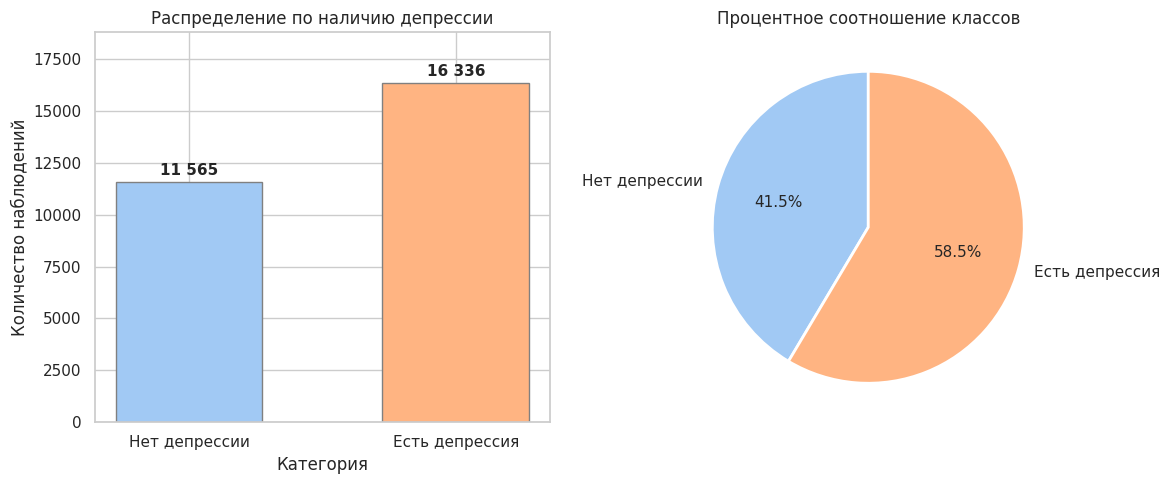

In [30]:
target = "Depression"
counts = df[target].value_counts().reindex([0, 1], fill_value=0)
percentages = counts / counts.sum() * 100

sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"

fig, axes = plt.subplots(figsize=(12, 5), ncols=2)

class_names = ["Нет депрессии", "Есть депрессия"]
palette = sns.color_palette("pastel", 2)

bars = axes[0].bar(
    class_names,
    counts.values,
    color=palette,
    edgecolor="gray",
    width=0.55
)

axes[0].set_title("Распределение по наличию депрессии")
axes[0].set_xlabel("Категория")
axes[0].set_ylabel("Количество наблюдений")
axes[0].set_ylim(0, counts.max() * 1.15)

for bar in bars:
    height = bar.get_height()
    axes[0].annotate(
        f"{int(height):,}".replace(",", " "),
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

axes[1].pie(
    percentages.values,
    labels=class_names,
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    colors=palette,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

axes[1].set_title("Процентное соотношение классов")

plt.tight_layout()
plt.show()


Доля Depression = 1 составляет 58,55%: дисбаланс есть, но не значительный.

In [31]:
numeric_cols = ["Age", "Academic Pressure", "Work Pressure", "CGPA", "Study Satisfaction",
                "Job Satisfaction", "Work/Study Hours", "Financial Stress"]
numeric_summary = df[numeric_cols].agg(["mean", "median", "std", "skew"]).T

numeric_summary.columns = [
    "Среднее",
    "Медиана",
    "Стандартное отклонение",
    "Асимметрия",
]

numeric_summary = numeric_summary.round(3)
numeric_summary

,Среднее,Медиана,Стандартное отклонение,Асимметрия
Age,25.822,25.00,4.906,0.132
Academic Pressure,3.141,3.00,1.381,-0.135
Work Pressure,0.000,0.00,0.044,108.594
CGPA,7.656,7.77,1.471,-0.113
Study Satisfaction,2.944,3.00,1.361,0.010
Job Satisfaction,0.001,0.00,0.044,74.106
Work/Study Hours,7.157,8.00,3.708,-0.455
Financial Stress,3.140,3.00,1.437,-0.130


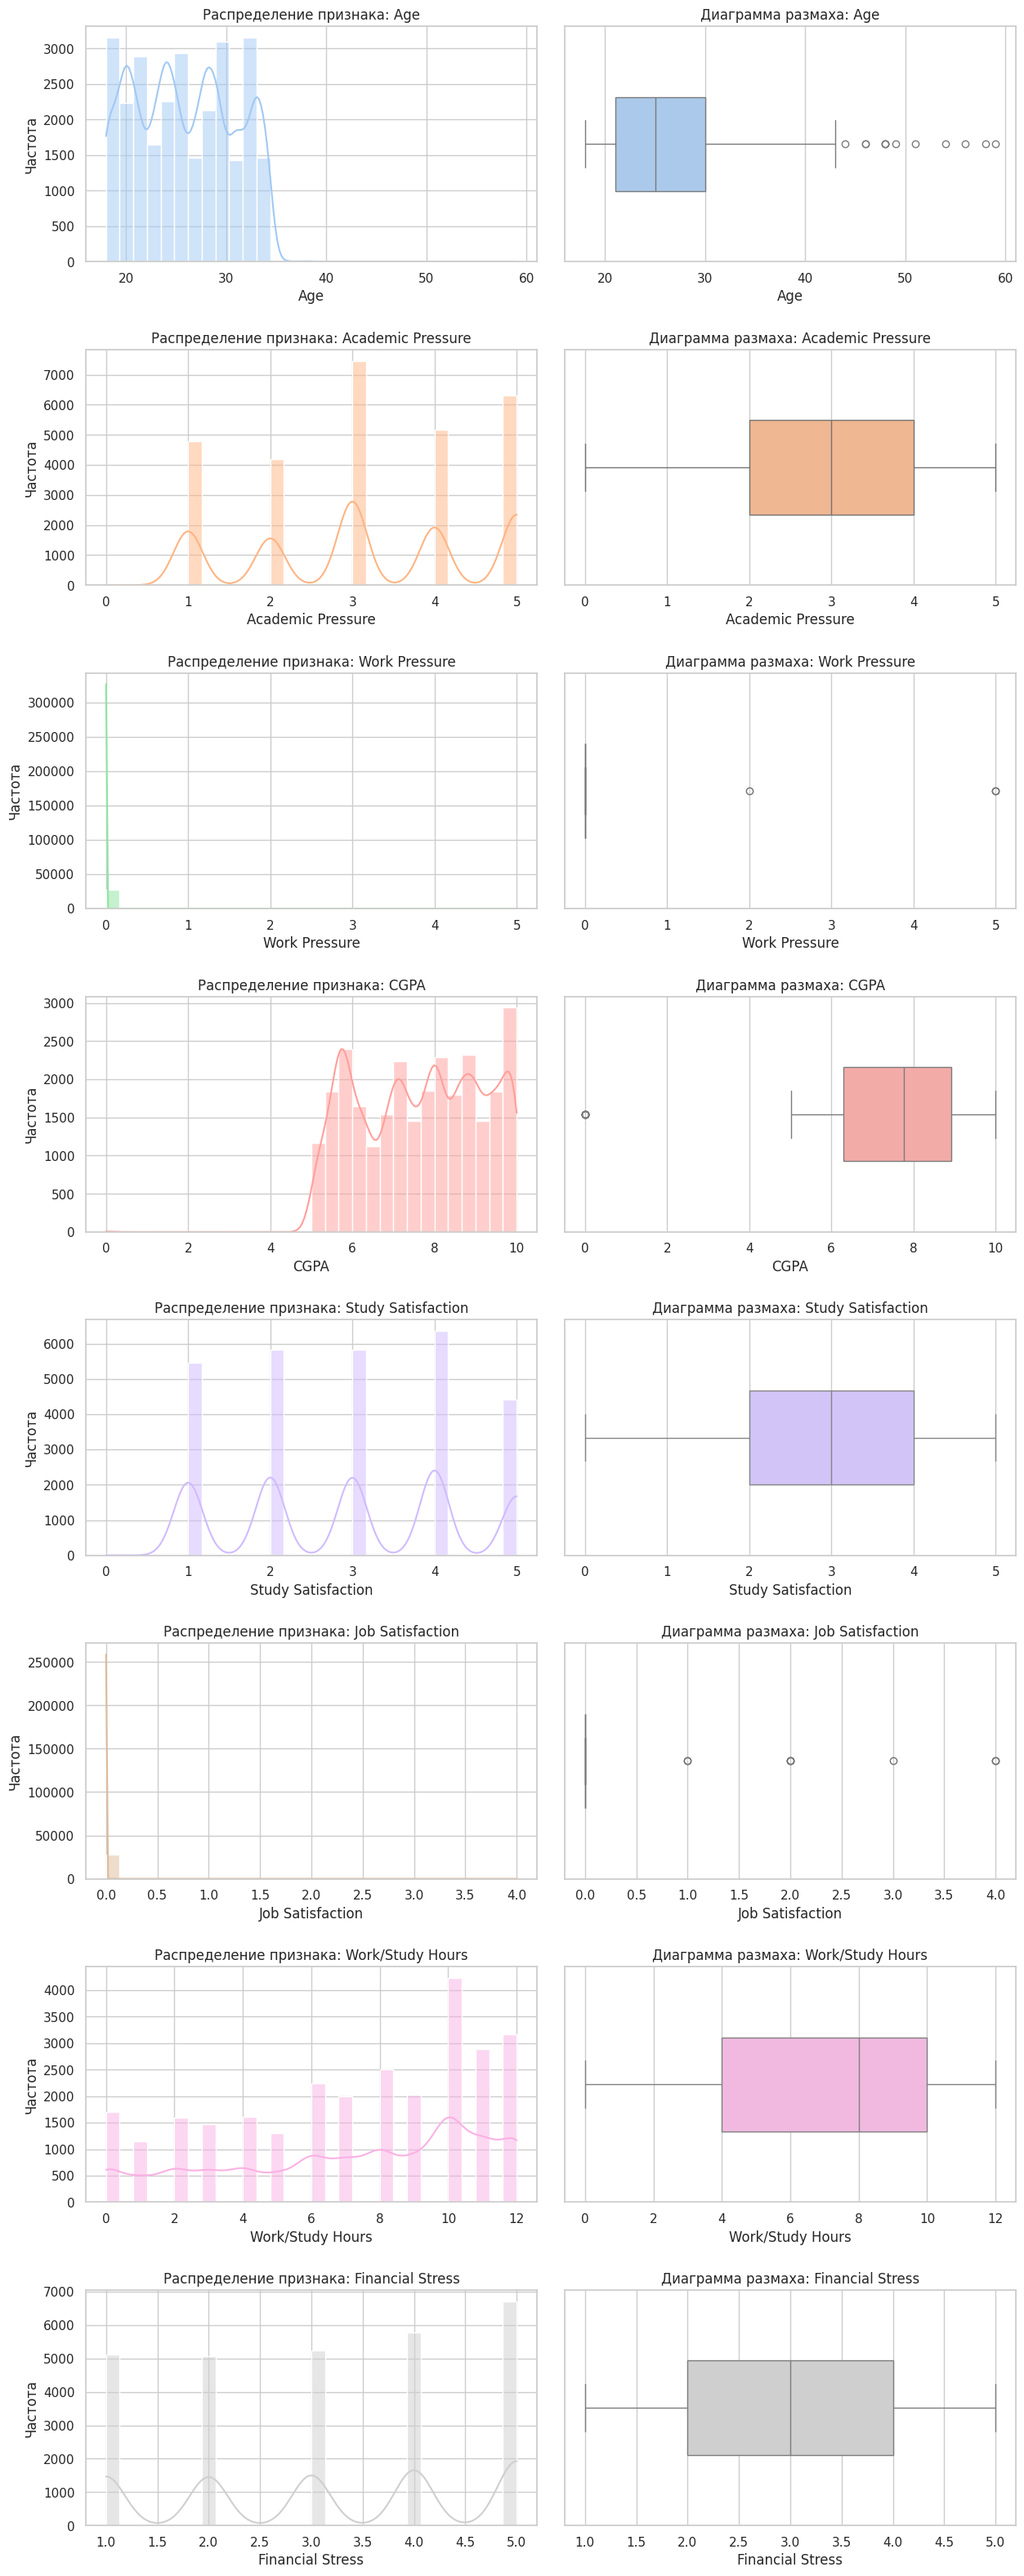

In [32]:
fig, axes = plt.subplots(
    nrows=len(numeric_cols),
    ncols=2,
    figsize=(13, 4 * len(numeric_cols)),
    squeeze=False
)

colors = sns.color_palette("pastel", len(numeric_cols))

for idx, feature in enumerate(numeric_cols):
    values = df[feature].dropna()

    sns.histplot(
        values,
        bins=30,
        kde=True,
        color=colors[idx],
        ax=axes[idx, 0]
    )

    axes[idx, 0].set_title(f"Распределение признака: {feature}")
    axes[idx, 0].set_xlabel(feature)
    axes[idx, 0].set_ylabel("Частота")

    sns.boxplot(
        x=values,
        color=colors[idx],
        ax=axes[idx, 1],
        width=0.4
    )

    axes[idx, 1].set_title(f"Диаграмма размаха: {feature}")
    axes[idx, 1].set_xlabel(feature)

plt.tight_layout(pad=2)
plt.show()

In [33]:
categories = ["Gender", "Sleep Duration", "Dietary Habits", "Degree", "Have you ever had suicidal thoughts ?", "Family History of Mental Illness"]

for feature in categories:
    frequency = df[feature].value_counts()
    percentage = df[feature].value_counts(normalize=True).mul(100).round(2)

    summary = pd.DataFrame({
        "Количество": frequency,
        "Доля (%)": percentage
    })

    print(f"\nРаспределение признака: {feature}")
    print(summary.to_string())
    print("-" * 50)



Распределение признака: Gender
        Количество  Доля (%)
Gender                      
Male         15547     55.72
Female       12354     44.28
--------------------------------------------------

Распределение признака: Sleep Duration
                   Количество  Доля (%)
Sleep Duration                         
Less than 5 hours        8310     29.78
7-8 hours                7346     26.33
5-6 hours                6183     22.16
More than 8 hours        6044     21.66
Others                     18      0.06
--------------------------------------------------

Распределение признака: Dietary Habits
                Количество  Доля (%)
Dietary Habits                      
Unhealthy            10317     36.98
Moderate              9921     35.56
Healthy               7651     27.42
Others                  12      0.04
--------------------------------------------------

Распределение признака: Degree
          Количество  Доля (%)
Degree                        
Class 12        6080   

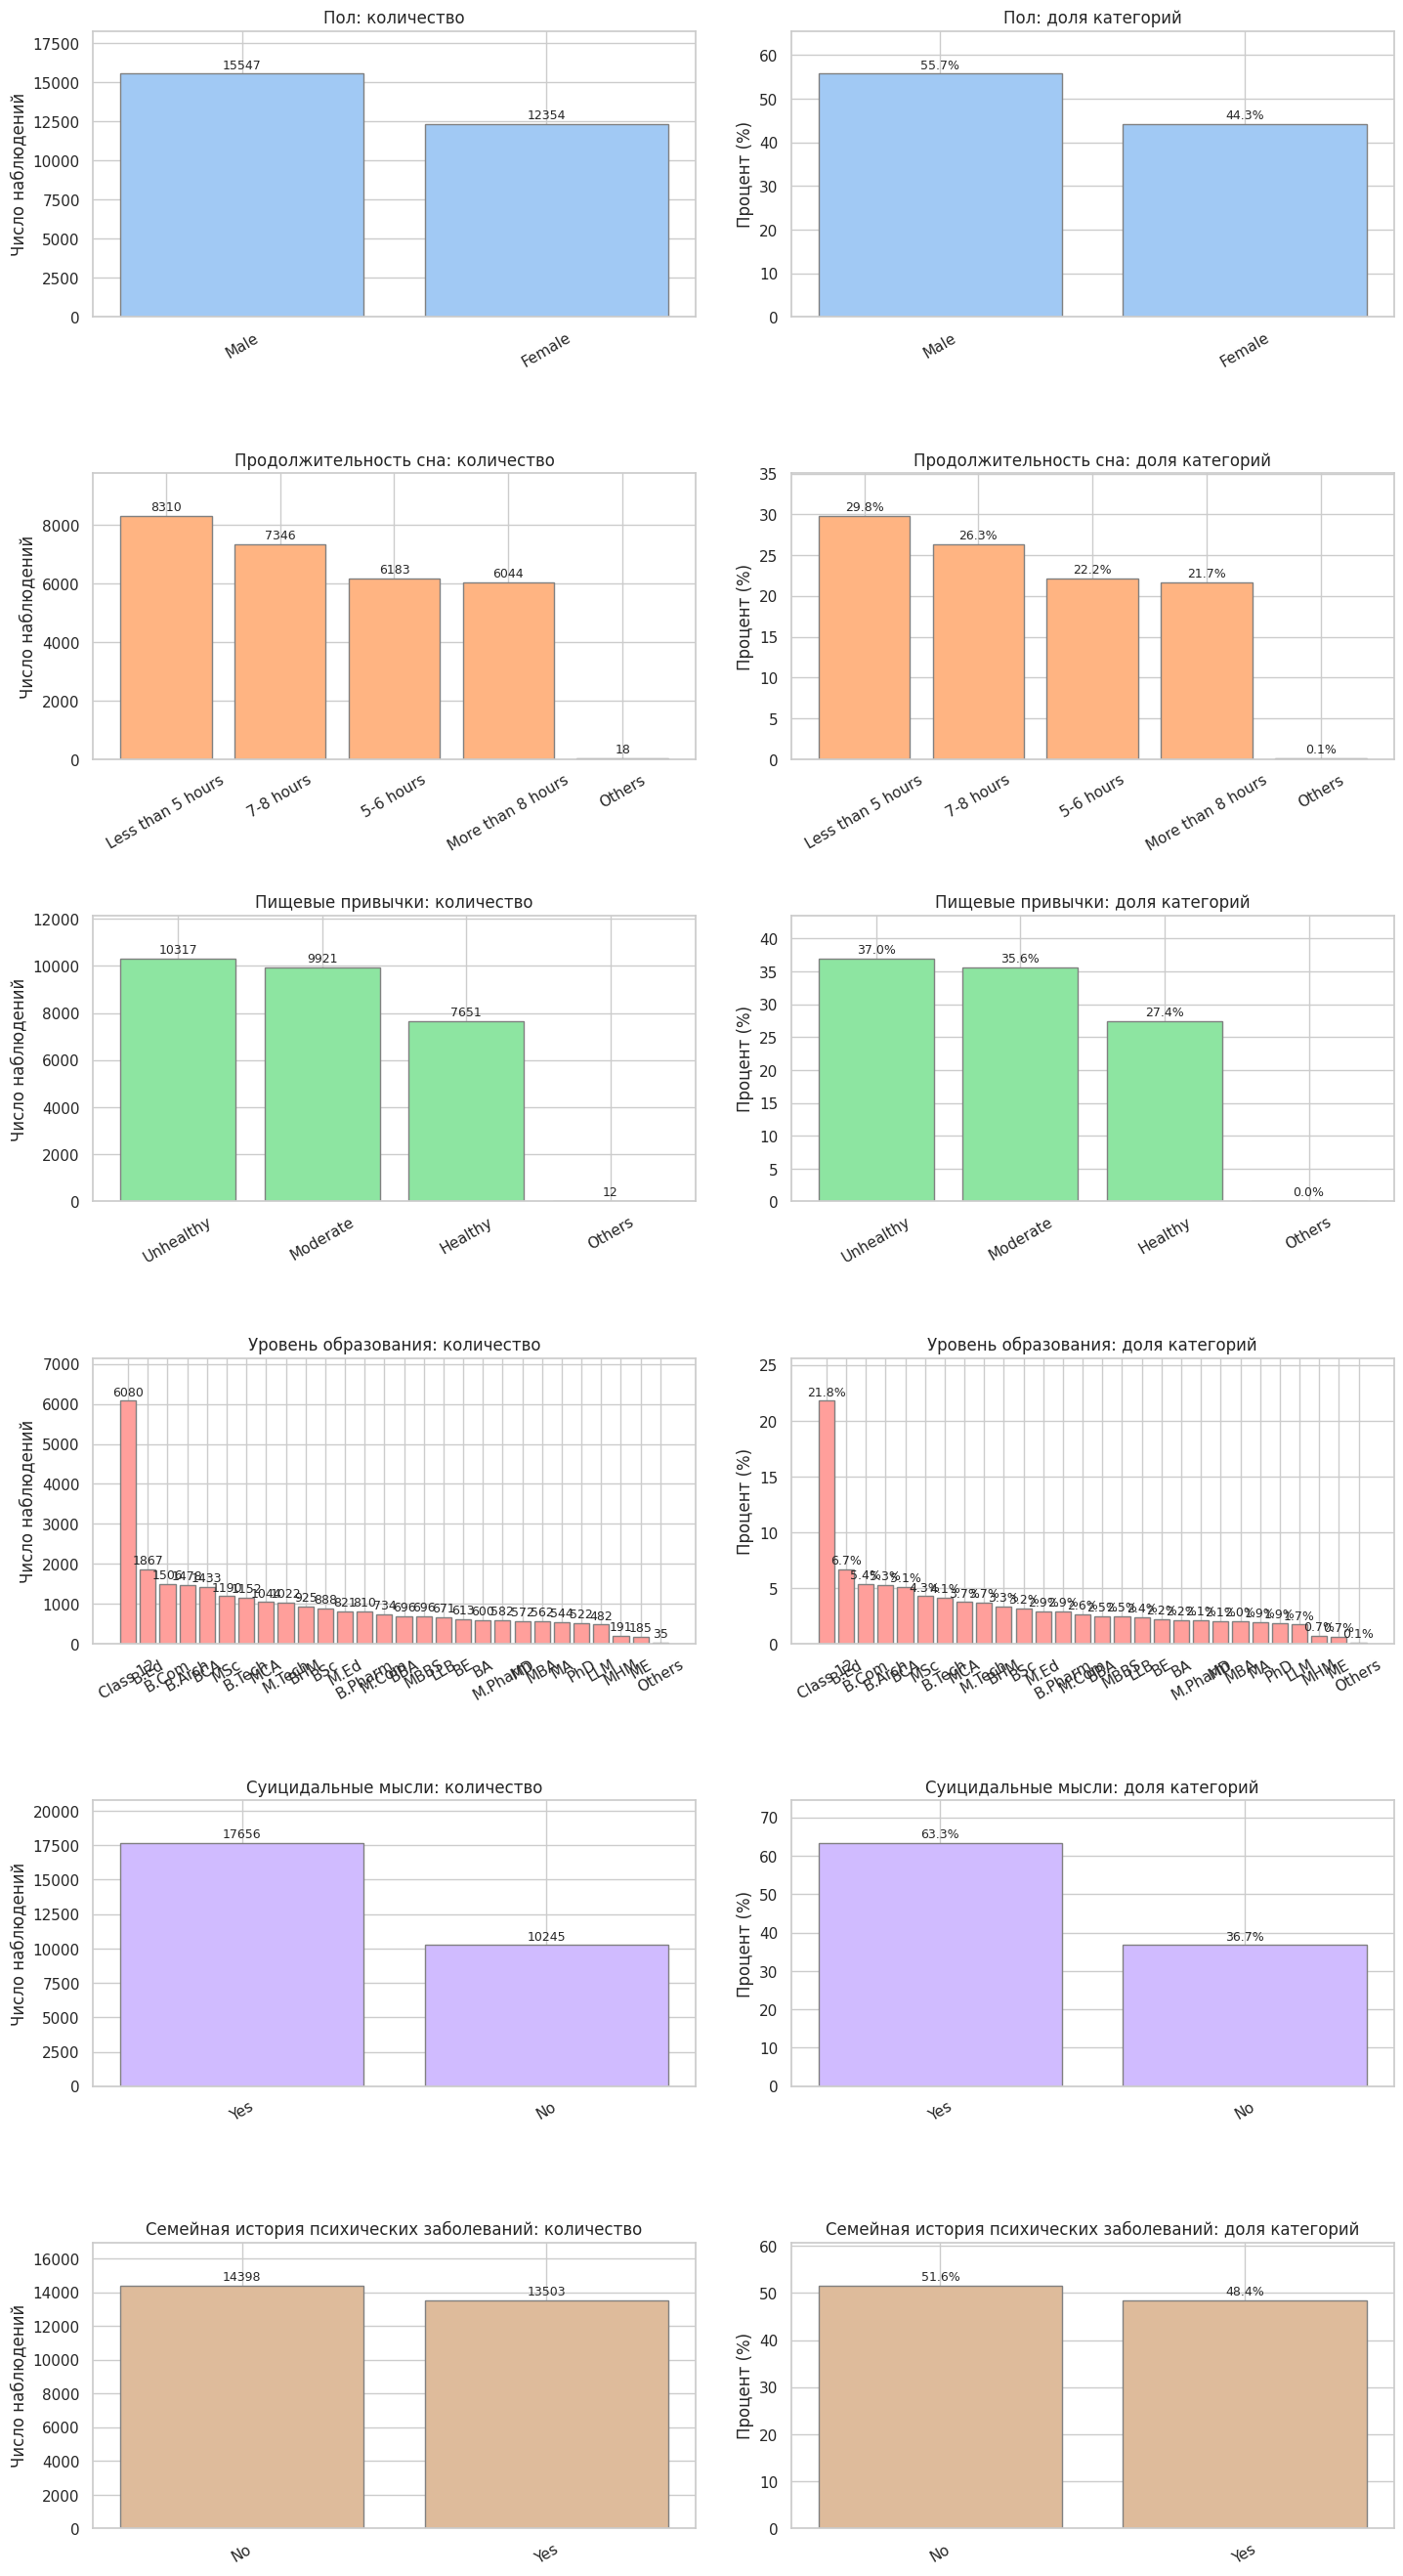

In [34]:
names = [
    "Пол",
    "Продолжительность сна",
    "Пищевые привычки",
    "Уровень образования",
    "Суицидальные мысли",
    "Семейная история психических заболеваний"
]

sns.set_theme(style="whitegrid")
colors = sns.color_palette("pastel")

fig, axes = plt.subplots(
    len(categories), 2,
    figsize=(15, 4.5 * len(categories))
)

for i, (feature, name) in enumerate(zip(categories, names)):
    counts = df[feature].value_counts()
    shares = counts / counts.sum() * 100

    axes[i, 0].bar(
        counts.index.astype(str),
        counts.values,
        color=colors[i % len(colors)],
        edgecolor="gray"
    )

    axes[i, 0].set_title(f"{name}: количество")
    axes[i, 0].set_ylabel("Число наблюдений")
    axes[i, 0].tick_params(axis="x", rotation=30)

    axes[i, 1].bar(
        shares.index.astype(str),
        shares.values,
        color=colors[i % len(colors)],
        edgecolor="gray"
    )

    axes[i, 1].set_title(f"{name}: доля категорий")
    axes[i, 1].set_ylabel("Процент (%)")
    axes[i, 1].tick_params(axis="x", rotation=30)

    for ax in axes[i]:
        for bar in ax.patches:
            value = bar.get_height()
            label = (
                f"{value:.1f}%"
                if ax == axes[i, 1]
                else f"{int(value)}"
            )

            ax.annotate(
                label,
                (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                fontsize=9
            )

        ax.set_ylim(0, ax.get_ylim()[1] * 1.12)

plt.tight_layout(pad=2.5)
plt.show()

## Проверка качества данных

In [35]:
quality = pd.Series({
    "Профессия отличается от Student": df["Profession"].ne("Student").sum(),
    "Редкие значения City (менее 10 наблюдений)": df["City"].map(df["City"].value_counts()).lt(10).sum(),
    "CGPA = 0": df["CGPA"].eq(0).sum(),
    "Academic Pressure = 0": df["Academic Pressure"].eq(0).sum(),
    "Study Satisfaction = 0": df["Study Satisfaction"].eq(0).sum(),
    "Sleep Duration = Others": df["Sleep Duration"].eq("Others").sum(),
    "Dietary Habits = Others": df["Dietary Habits"].eq("Others").sum()
})
quality.to_frame("Количество")

,Количество
Профессия отличается от Student,31
Редкие значения City (менее 10 наблюдений),26
CGPA = 0,9
Academic Pressure = 0,9
Study Satisfaction = 0,10
Sleep Duration = Others,18
Dietary Habits = Others,12


In [36]:
pd.DataFrame({
    "Уникальных значений": df[numeric_cols].nunique(),
    "Доля самого частого значения (%)": df[numeric_cols].apply(lambda x: x.value_counts(normalize=True).iloc[0] * 100)
}).round(3)

,Уникальных значений,Доля самого частого значения (%)
Age,34,8.093
Academic Pressure,6,26.745
Work Pressure,3,99.989
CGPA,332,2.943
Study Satisfaction,6,22.791
Job Satisfaction,5,99.971
Work/Study Hours,13,15.175
Financial Stress,5,24.067


## Корреляции признаков

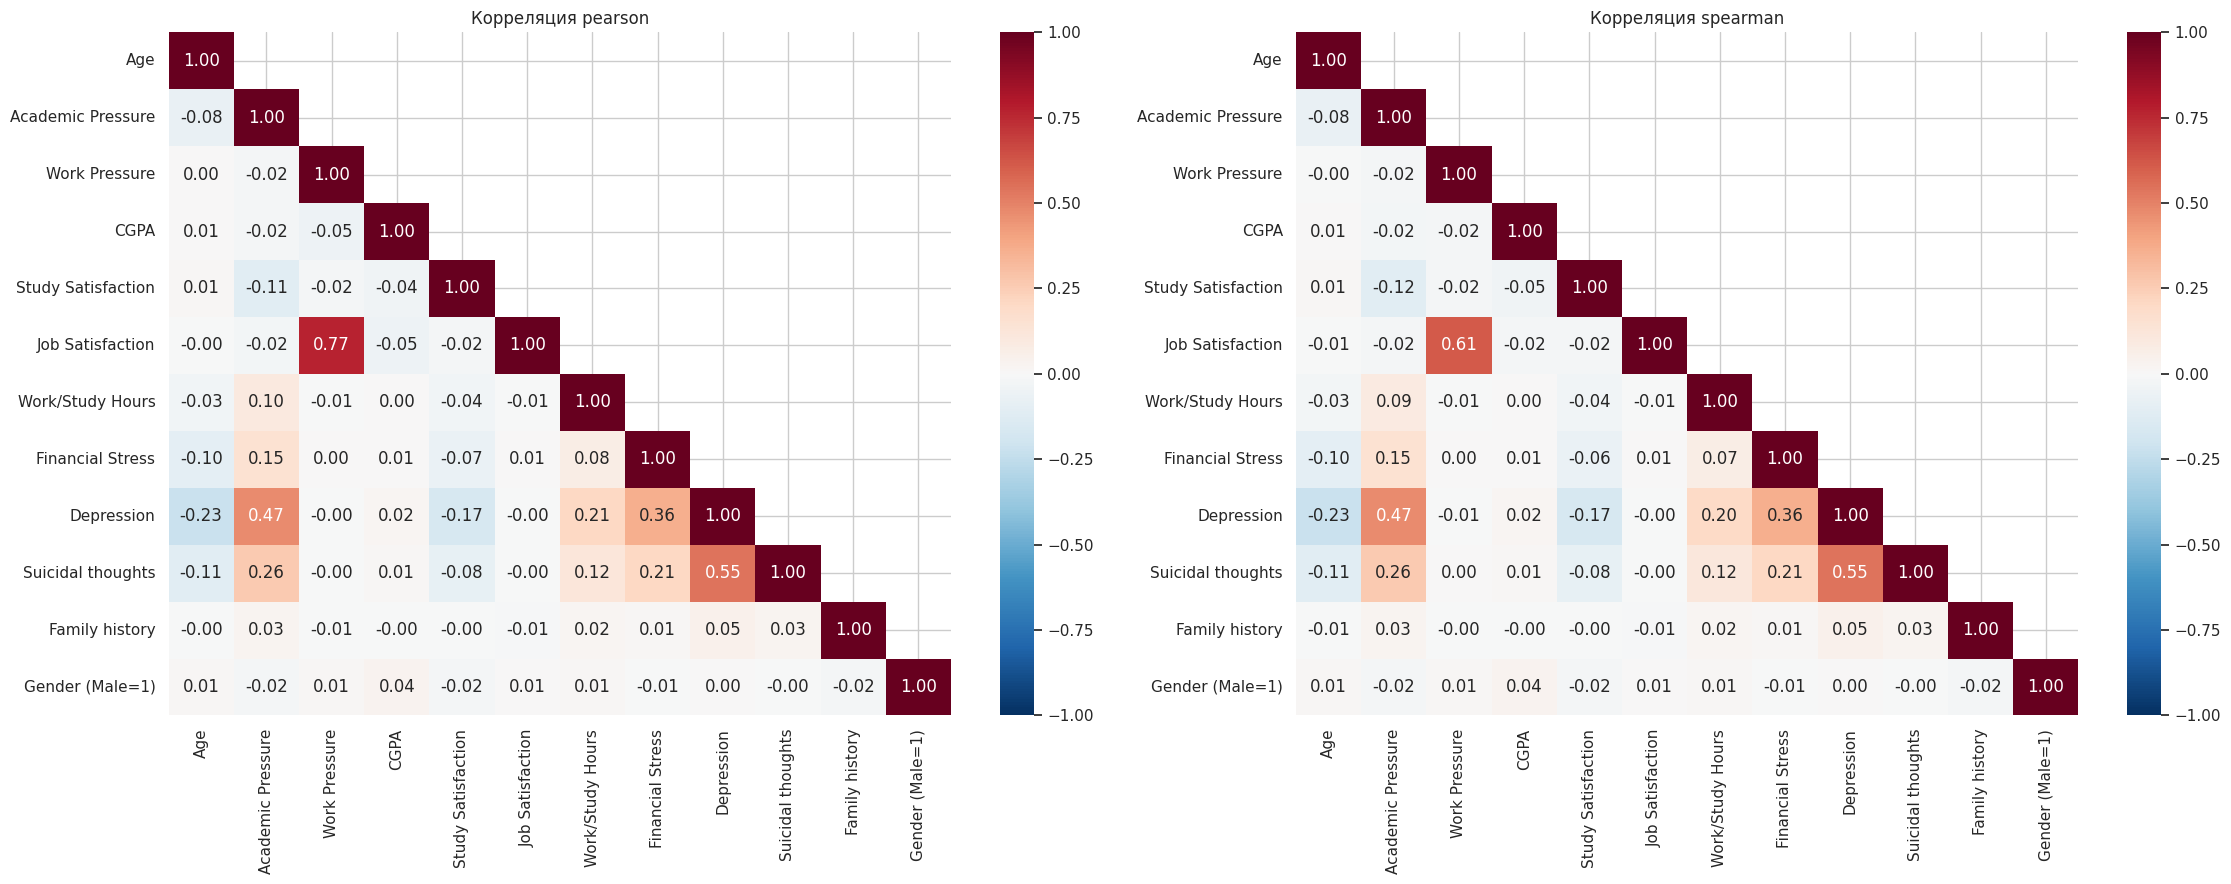

In [37]:
association_data = df[numeric_cols + [target]].copy()
association_data["Suicidal thoughts"] = df["Have you ever had suicidal thoughts ?"].map({"No": 0, "Yes": 1})
association_data["Family history"] = df["Family History of Mental Illness"].map({"No": 0, "Yes": 1})
association_data["Gender (Male=1)"] = df["Gender"].map({"Female": 0, "Male": 1})
fig, axes = plt.subplots(1, 2, figsize=(23, 9))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = association_data.corr(method=method)
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
                cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax)
    ax.set_title(f"Корреляция {method}")
plt.tight_layout()
plt.show()

In [38]:
target_correlations = pd.DataFrame({
    "Pearson": association_data.corr(method="pearson")[target],
    "Spearman": association_data.corr(method="spearman")[target]
}).drop(index=target)
target_correlations = target_correlations.loc[target_correlations["Spearman"].abs().sort_values(ascending=False).index]
target_correlations.round(3)

,Pearson,Spearman
Suicidal thoughts,0.546,0.546
Academic Pressure,0.475,0.472
Financial Stress,0.364,0.363
Age,-0.226,-0.225
Work/Study Hours,0.209,0.201
Study Satisfaction,-0.168,-0.168
Family history,0.053,0.053
CGPA,0.022,0.022
Work Pressure,-0.003,-0.005
Job Satisfaction,-0.003,-0.003


Мы видим очевидное, стресс напрямую кореллирует с депрессией, а так же суицидальные мысли, что в целом является следствием психического состояния.

## Числовые признаки и депрессия

In [39]:
df.groupby(target)[numeric_cols].agg(["mean", "median"]).round(3)

Age        Academic Pressure        Work Pressure          CGPA        Study Satisfaction        Job Satisfaction         \
              mean median              mean median          mean median   mean median               mean median             mean median   
Depression                                                                                                                                
0           27.142   28.0             2.362    2.0         0.001    0.0  7.617   7.64              3.216    3.0            0.001    0.0   
1           24.888   24.0             3.693    4.0         0.000    0.0  7.684   7.85              2.751    3.0            0.001    0.0   

           Work/Study Hours        Financial Stress         
                       mean median             mean median  
Depression                                                  
0                     6.238    6.0            2.519    2.0  
1                     7.808    9.0            3.580    4.0

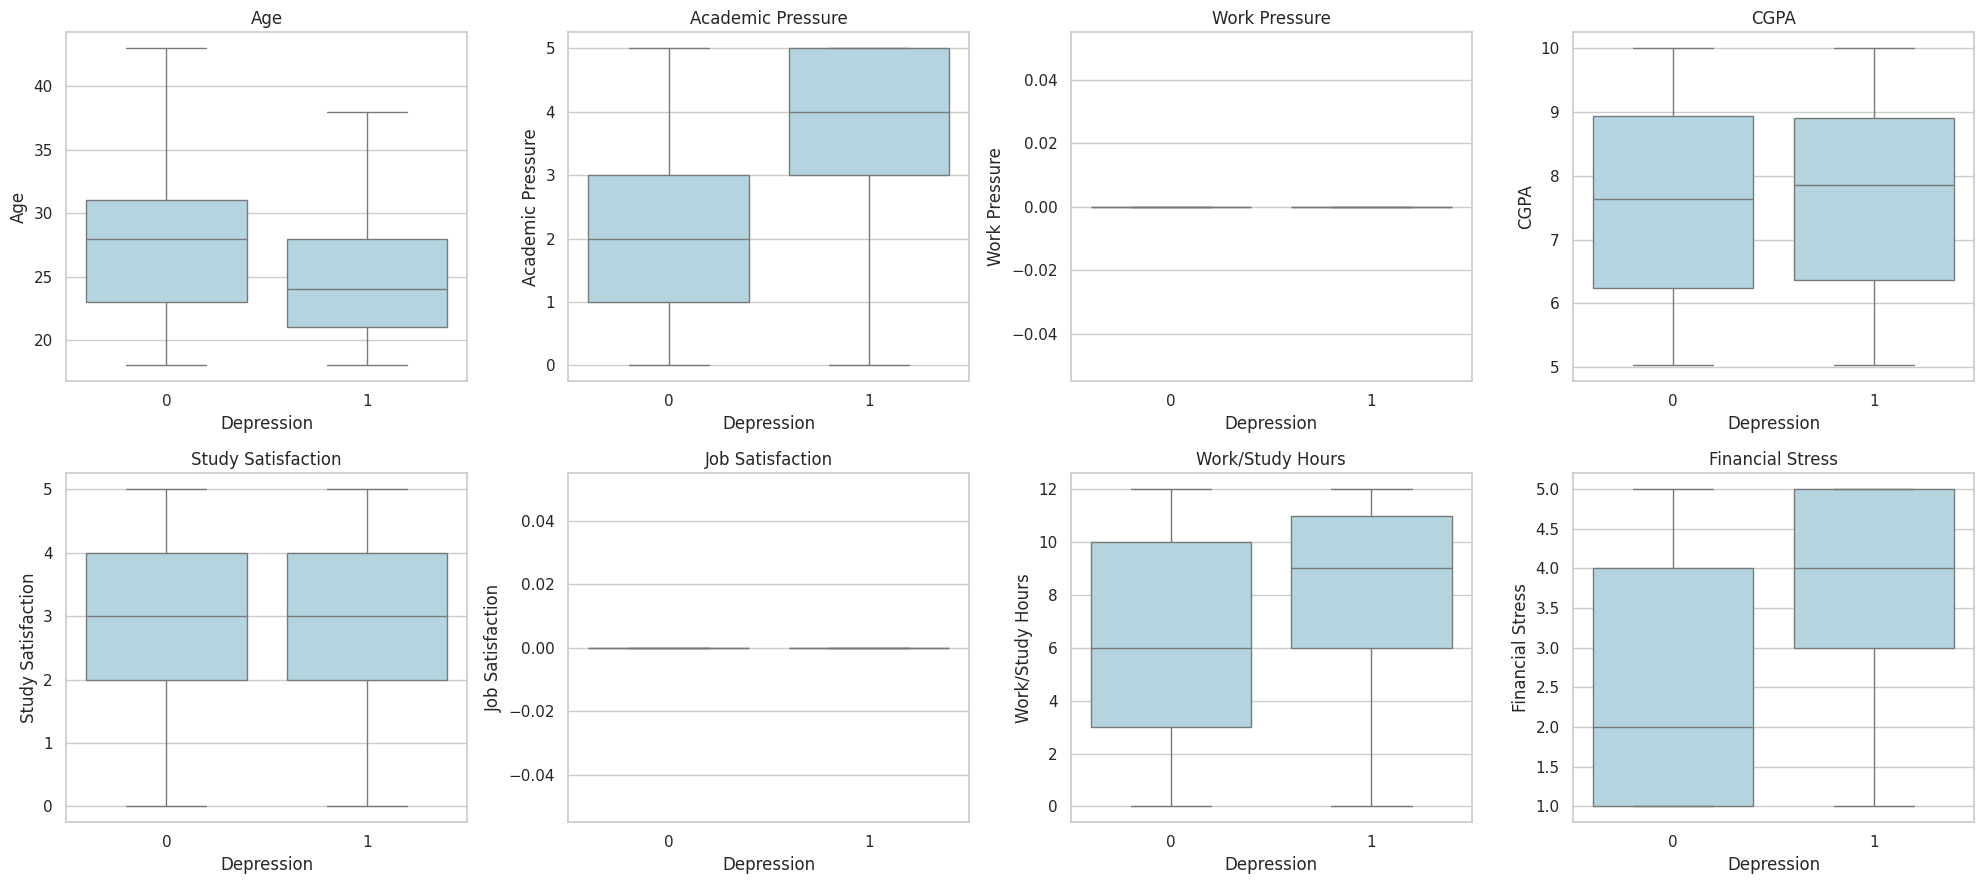

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, feature in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, x=target, y=feature, ax=ax, color="lightblue", showfliers=False)
    ax.set_title(feature)
    ax.set_xlabel("Depression")
plt.tight_layout()
plt.show()

## Категориальные признаки и депрессия

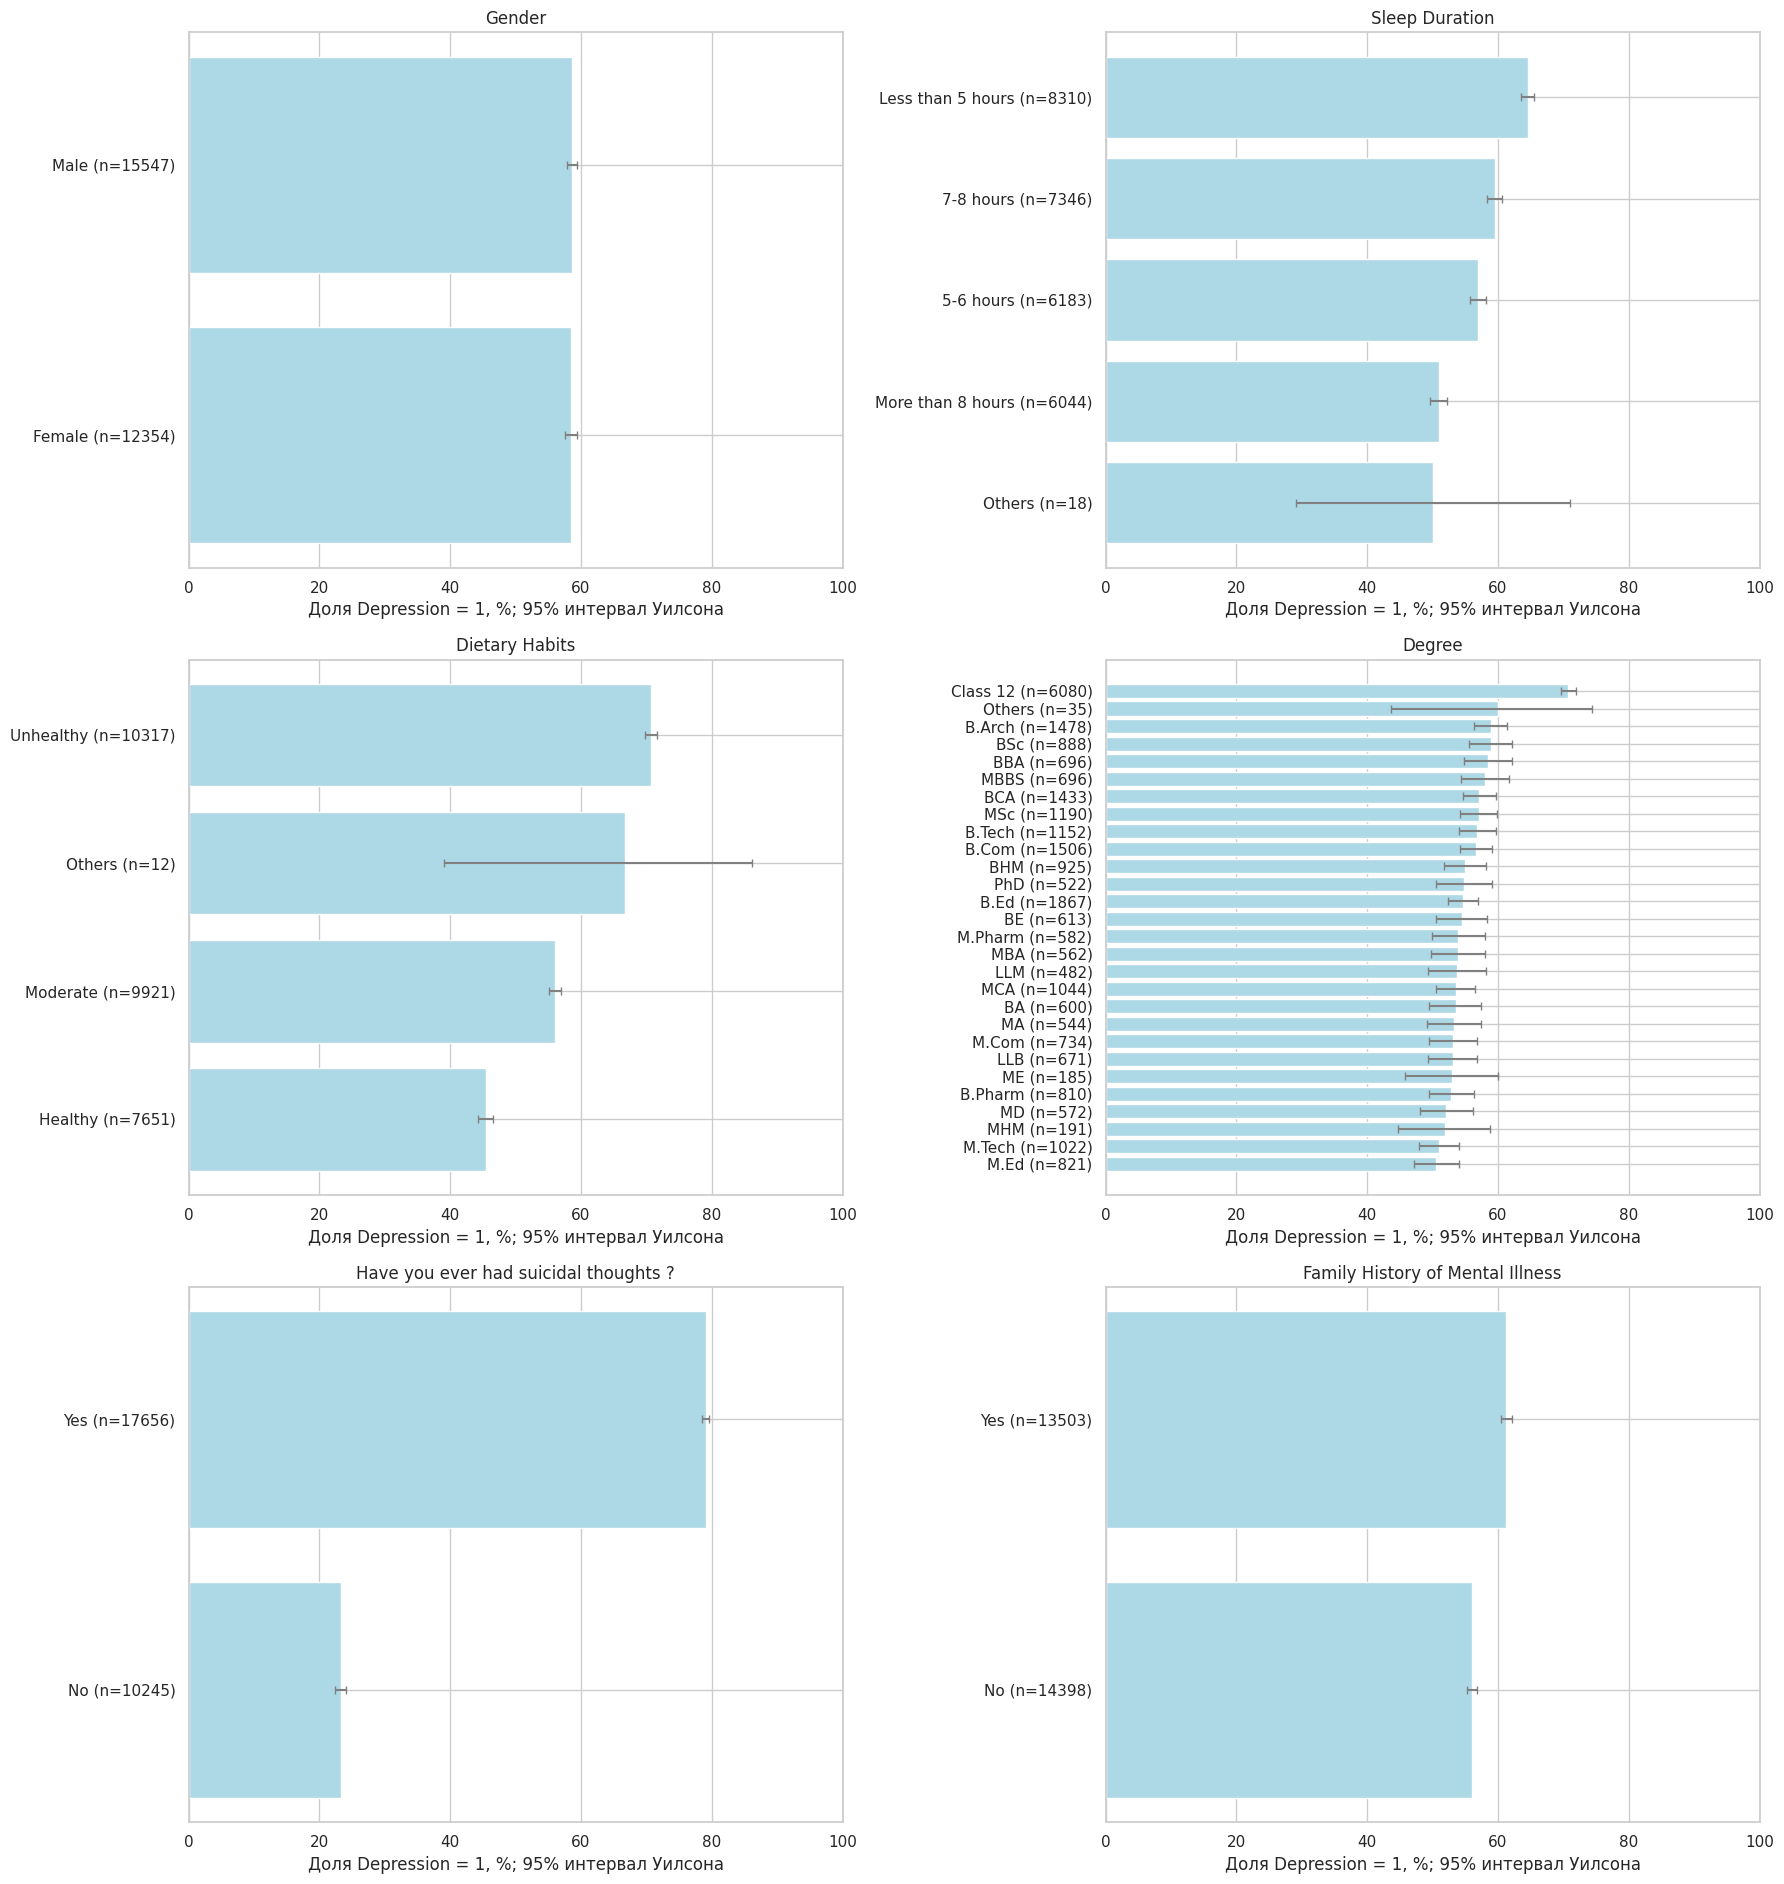

In [41]:
category_tables = {}
for feature in categories + ["Profession", "City"]:
    summary = df.groupby(feature, observed=True)[target].agg(n="size", depressed="sum", rate="mean")
    z = 1.96
    denominator = 1 + z ** 2 / summary["n"]
    center = (summary["rate"] + z ** 2 / (2 * summary["n"])) / denominator
    half = z * np.sqrt(summary["rate"] * (1 - summary["rate"]) / summary["n"] + z ** 2 / (4 * summary["n"] ** 2)) / denominator
    summary["lower"] = (center - half) * 100
    summary["upper"] = (center + half) * 100
    summary["rate"] *= 100
    category_tables[feature] = summary
fig, axes = plt.subplots(3, 2, figsize=(18, 19))
for ax, feature in zip(axes.flat, categories):
    summary = category_tables[feature].sort_values("rate")
    positions = np.arange(len(summary))
    ax.barh(positions, summary["rate"], color="lightblue")
    ax.errorbar(summary["rate"], positions,
                xerr=np.vstack([np.maximum(0, summary["rate"] - summary["lower"]), np.maximum(0, summary["upper"] - summary["rate"])]),
                fmt="none", ecolor="gray", capsize=3)
    ax.set_yticks(positions, [f"{label} (n={count})" for label, count in zip(summary.index, summary["n"])])
    ax.set_xlim(0, 100)
    ax.set_title(feature)
    ax.set_xlabel("Доля Depression = 1, %; 95% интервал Уилсона")
plt.tight_layout()
plt.show()

In [42]:
categorical_associations = []
for feature in categories + ["Profession", "City"]:
    table = pd.crosstab(df[feature], df[target])
    chi2, p_value, dof, expected = stats.chi2_contingency(table, correction=False)
    total = table.to_numpy().sum()
    r, k = table.shape
    phi2 = max(0, chi2 / total - (r - 1) * (k - 1) / (total - 1))
    r_corrected = r - (r - 1) ** 2 / (total - 1)
    k_corrected = k - (k - 1) ** 2 / (total - 1)
    cramers_v = np.sqrt(phi2 / min(r_corrected - 1, k_corrected - 1))
    categorical_associations.append([feature, cramers_v, p_value, (expected < 5).mean() * 100])
categorical_associations = pd.DataFrame(categorical_associations, columns=["Признак", "V Крамера (с поправкой)", "p-value", "Ожидаемые частоты < 5 (%)"])
order = categorical_associations["p-value"].sort_values().index
adjusted = (categorical_associations.loc[order, "p-value"].to_numpy() * (len(order) - np.arange(len(order))))
categorical_associations.loc[order, "p-value (Holm)"] = np.minimum(1, np.maximum.accumulate(adjusted))
categorical_associations.sort_values("V Крамера (с поправкой)", ascending=False).round(6)

,Признак,V Крамера (с поправкой),p-value,Ожидаемые частоты < 5 (%),p-value (Holm)
4,Have you ever had suicidal thoughts ?,0.546254,0.000000,0.000000,0.000000
2,Dietary Habits,0.207359,0.000000,12.500000,0.000000
3,Degree,0.134452,0.000000,0.000000,0.000000
1,Sleep Duration,0.098891,0.000000,0.000000,0.000000
7,City,0.070057,0.000000,42.307692,0.000000
5,Family History of Mental Illness,0.053095,0.000000,0.000000,0.000000
6,Profession,0.006794,0.353859,92.857143,0.707719
0,Gender,0.000000,0.764379,0.000000,0.764379


## Итоги

In [44]:
top_links = target_correlations["Spearman"].abs().nlargest(5).index
print("Наиболее выраженные связи с Depression (Spearman):")
print(target_correlations.loc[top_links, "Spearman"].round(3).to_string())
print("\nНаибольшие связи категориальных признаков:")
print(categorical_associations.nlargest(3, "V Крамера (с поправкой)")[["Признак", "V Крамера (с поправкой)"]].round(3).to_string(index=False))

Наиболее выраженные связи с Depression (Spearman):
Suicidal thoughts    0.546
Academic Pressure    0.472
Financial Stress     0.363
Age                 -0.225
Work/Study Hours     0.201

Наибольшие связи категориальных признаков:
                              Признак  V Крамера (с поправкой)
Have you ever had suicidal thoughts ?                    0.546
                       Dietary Habits                    0.207
                               Degree                    0.134


Вывод из данных таков, стресс и его разные виды напрмяю кореллирует с депрессией, в то время как влияние пола, возраста и образа жизни существенно слабее